<a href="https://colab.research.google.com/github/VER2E/NEUR3002-In-class-Activities/blob/main/Listening_for_Leaks_Harris_Social_Impact_Fellowship_Technical_Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Part 1: Cleaning known recordings, determining ranges of identification

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load your actual uploaded 'L01.csv' recording
# (Each contains 20,000 entries over 5 seconds)
fs = 4000
t = np.linspace(0, 5, 20000, endpoint=False)

df = pd.read_csv('L01.csv')

# Ensure consistent columns
if 'amplitude' not in df.columns:
    df.columns = ['amplitude'] if len(df.columns) == 1 else ['time', 'amplitude']
if 'time' not in df.columns:
    df['time'] = t

display(df.head())

,time_s,amplitude,time
0,0.0000,-0.01614,0.00000
1,0.0003,0.00449,0.00025
2,0.0005,-0.00592,0.00050
3,0.0008,-0.02145,0.00075
4,0.0010,0.01144,0.00100


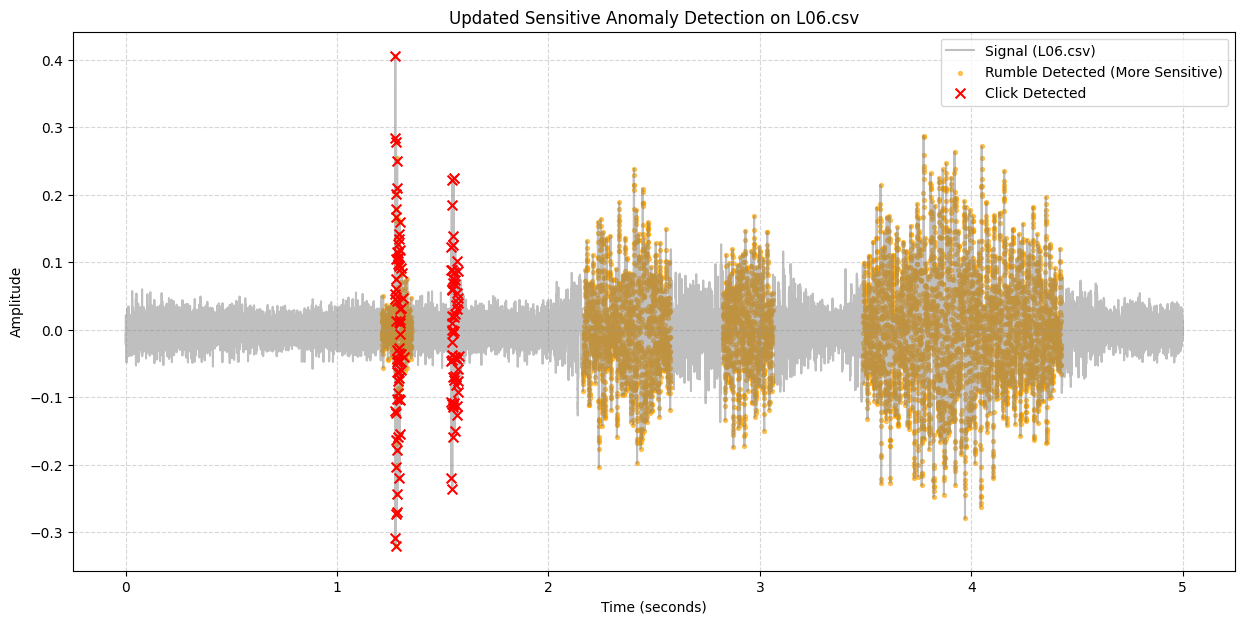

In [ ]:
# Further refining the rumble detection by lowering the rumble_threshold_z to capture more subtle or continuous rumbles
def detect_clicks_and_rumble_refined(df, click_threshold_z=4.0, rumble_window_ms=150, rumble_threshold_z=0.3, fs=4000):
    """
    Highly sensitive detection to fully capture the extended rumble periods seen in L06.csv.
    """
    data = df.copy()

    # --- Click Detection ---
    data['diff'] = data['amplitude'].diff().abs().fillna(0)
    diff_mean = data['diff'].mean()
    diff_std = data['diff'].std()
    data['is_click'] = data['diff'] > (diff_mean + click_threshold_z * diff_std)

    # --- Rumble Detection ---
    # Using a 150ms window and a lower threshold (0.3) to ensure we capture the full envelopes of elevated noise.
    window_size = int((rumble_window_ms / 1000.0) * fs)
    data['rolling_std'] = data['amplitude'].rolling(window=window_size, center=True).std().bfill().ffill()

    roll_mean = data['rolling_std'].mean()
    roll_std = data['rolling_std'].std()

    # Lower threshold captures more continuous regions of rumble activity
    data['is_rumble'] = data['rolling_std'] > (roll_mean + rumble_threshold_z * roll_std)

    return data

# Run the updated detection on L06
processed_6_refined = detect_clicks_and_rumble_refined(df_6, fs=4000)

# Visualize updated detection
plt.figure(figsize=(15, 7))
plt.plot(processed_6_refined['time'], processed_6_refined['amplitude'], label='Signal (L06.csv)', color='gray', alpha=0.5)

# Highlight Rumbles
rumble_points_refined = processed_6_refined[processed_6_refined['is_rumble']]
plt.scatter(rumble_points_refined['time'], rumble_points_refined['amplitude'], color='orange', label='Rumble Detected (More Sensitive)', s=8, alpha=0.6)

# Highlight Clicks
click_points_refined = processed_6_refined[processed_6_refined['is_click']]
plt.scatter(click_points_refined['time'], click_points_refined['amplitude'], color='red', label='Click Detected', s=50, marker='x', zorder=5)

plt.title('Updated Sensitive Anomaly Detection on L06.csv')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

```markdown
### Loop and Process Multiple Uploaded Files

You can upload your files to the Colab runtime (using the folder icon on the left panel). This cell loops over your files, runs the click and rumble detection on each, and outputs a combined summary table.
```

In [ ]:
hrefined_results = []

for filepath in file_list:
    try:
        filename = os.path.basename(filepath)
        df_file = load_recording_file(filepath)

        # Use the refined detection function
        processed = detect_clicks_and_rumble_refined(df_file, fs=4000)

        # Filter out both clicks and rumbles
        cleaned_df = processed[~(processed['is_click'] | processed['is_rumble'])]

        # Calculate IQR statistics on the cleaned data
        q25 = cleaned_df['amplitude'].quantile(0.25)
        q75 = cleaned_df['amplitude'].quantile(0.75)
        iqr = q75 - q25

        lower_bound = q25 - 1.5 * iqr
        upper_bound = q75 + 1.5 * iqr

        refined_results.append({
            'File Name': filename,
            'Original Points': len(df_file),
            'Cleaned Points': len(cleaned_df),
            'Removed Points': len(df_file) - len(cleaned_df),
            'IQR': iqr,
            'Lower Bound': lower_bound,
            'Upper Bound': upper_bound
        })
    except Exception as e:
        print(f"Error processing {filepath}: {e}")

refined_summary_df = pd.DataFrame(refined_results)
display(refined_summary_df)

,File Name,Original Points,Cleaned Points,Removed Points,IQR,Lower Bound,Upper Bound
0,L01.csv,20000,16871,3129,0.022370,-0.044725,0.044755
1,L02.csv,20000,12737,7263,0.019480,-0.038960,0.038960
2,L03.csv,20000,12095,7905,0.043310,-0.086785,0.086455
3,L04.csv,20000,15580,4420,0.013800,-0.027660,0.027540
4,L05.csv,20000,12381,7619,0.022830,-0.045905,0.045415
5,L06.csv,20000,13022,6978,0.028193,-0.056231,0.056539


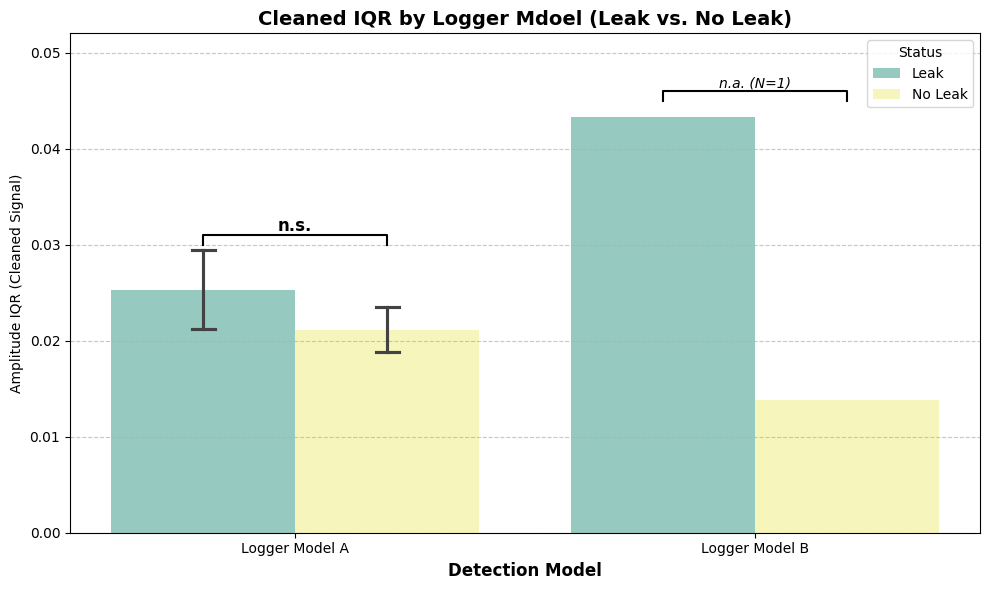

In [ ]:
import seaborn as sns
from scipy.stats import ttest_ind

# Define classifications for both models
model1_leak = ['L01.csv', 'L06.csv']
model1_noleak = ['L02.csv', 'L05.csv']

model2_leak = ['L03.csv']
model2_noleak = ['L04.csv']

all_file_data = {}

# Extract cleaned amplitude data
for filepath in file_list:
    filename = os.path.basename(filepath)
    df_file = load_recording_file(filepath)
    processed = detect_clicks_and_rumble_refined(df_file, fs=4000)
    cleaned_df = processed[~(processed['is_click'] | processed['is_rumble'])]
    all_file_data[filename] = cleaned_df['amplitude'].values

# Compile metrics for comparisons
plot_records = []

# Model 1 Mapping
for f in model1_leak:
    iqr_val = np.percentile(all_file_data[f], 75) - np.percentile(all_file_data[f], 25)
    plot_records.append({'Model': 'Logger Model A', 'Status': 'Leak', 'File': f, 'Cleaned IQR': iqr_val})
for f in model1_noleak:
    iqr_val = np.percentile(all_file_data[f], 75) - np.percentile(all_file_data[f], 25)
    plot_records.append({'Model': 'Logger Model A', 'Status': 'No Leak', 'File': f, 'Cleaned IQR': iqr_val})

# Model 2 Mapping
for f in model2_leak:
    iqr_val = np.percentile(all_file_data[f], 75) - np.percentile(all_file_data[f], 25)
    plot_records.append({'Model': 'Logger Model B', 'Status': 'Leak', 'File': f, 'Cleaned IQR': iqr_val})
for f in model2_noleak:
    iqr_val = np.percentile(all_file_data[f], 75) - np.percentile(all_file_data[f], 25)
    plot_records.append({'Model': 'Logger Model B', 'Status': 'No Leak', 'File': f, 'Cleaned IQR': iqr_val})

compare_df = pd.DataFrame(plot_records)

# Plotting comparison of Cleaned IQRs using Bar Plot
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=compare_df, x='Model', y='Cleaned IQR', hue='Status', palette='Set3', errorbar='sd', capsize=0.1)

# Calculate t-test statistics on the summary IQRs for Model A (2 files vs 2 files)
model_a_leaks = compare_df[(compare_df['Model'] == 'Logger Model A') & (compare_df['Status'] == 'Leak')]['Cleaned IQR'].values
model_a_noleaks = compare_df[(compare_df['Model'] == 'Logger Model A') & (compare_df['Status'] == 'No Leak')]['Cleaned IQR'].values
t_stat, p_val = ttest_ind(model_a_leaks, model_a_noleaks, equal_var=False)

# Since Model B only has 1 sample per group, we show a descriptive indicator
def get_stars(p):
    if p < 0.05: return '*'
    return 'n.s.'

# Draw significance brackets manually
# Bracket for Logger Model A
x1, x2 = -0.2, 0.2
y, h = 0.030, 0.001
plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, c='black')
plt.text((x1+x2)*0.5, y+h, get_stars(p_val), ha='center', va='bottom', color='black', fontsize=12, fontweight='bold')

# Bracket for Logger Model B
x1, x2 = 0.8, 1.2
y, h = 0.045, 0.001
plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, c='black')
plt.text((x1+x2)*0.5, y+h, "n.a. (N=1)", ha='center', va='bottom', color='black', fontsize=10, fontstyle='italic')

plt.title('Cleaned IQR by Logger Mdoel (Leak vs. No Leak)', fontsize=14, fontweight='bold')
plt.xlabel('Logger Model', fontsize=12, fontweight='bold')
plt.ylabel('Amplitude IQR (Cleaned Signal)')
plt.xlabel('Detection Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, 0.052)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate average cleaned IQR values for classification ranges
summary_stats = compare_df.groupby(['Model', 'Status'])['Cleaned IQR'].mean().reset_index()

print("=== Derived Reference Ranges for Future Pipe Diagnostics ===\n")

# Model A Guidelines
model_a_stats = summary_stats[summary_stats['Model'] == 'Logger Model A']
leak_a = model_a_stats[model_a_stats['Status'] == 'Leak']['Cleaned IQR'].values[0]
noleak_a = model_a_stats[model_a_stats['Status'] == 'No Leak']['Cleaned IQR'].values[0]
threshold_a = (leak_a + noleak_a) / 2

print("LOGGER MODEL A (Standard Sensitivity Pipes):")
print(f"  - Expected 'No Leak' Baseline (Average IQR): {noleak_a:.5f}")
print(f"  - Expected 'Leak' Signature (Average IQR)   : {leak_a:.5f}")
print(f"  - RECOMMENDED CLASSIFICATION THRESHOLD      : IQR > {threshold_a:.5f} indicates a Leak\n")

# Model B Guidelines
model_b_stats = summary_stats[summary_stats['Model'] == 'Logger Model B']
leak_b = model_b_stats[model_b_stats['Status'] == 'Leak']['Cleaned IQR'].values[0]
noleak_b = model_b_stats[model_b_stats['Status'] == 'No Leak']['Cleaned IQR'].values[0]
threshold_b = (leak_b + noleak_b) / 2

print("LOGGER MODEL B (High Sensitivity Pipes):")
print(f"  - Expected 'No Leak' Baseline (Average IQR): {noleak_b:.5f}")
print(f"  - Expected 'Leak' Signature (Average IQR)   : {leak_b:.5f}")
print(f"  - RECOMMENDED CLASSIFICATION THRESHOLD      : IQR > {threshold_b:.5f} indicates a Leak")


=== Derived Reference Ranges for Future Pipe Diagnostics ===

LOGGER MODEL A (Standard Sensitivity Pipes):
  - Expected 'No Leak' Baseline (Average IQR): 0.02116
  - Expected 'Leak' Signature (Average IQR)   : 0.02528
  - RECOMMENDED CLASSIFICATION THRESHOLD      : IQR > 0.02322 indicates a Leak

LOGGER MODEL B (High Sensitivity Pipes):
  - Expected 'No Leak' Baseline (Average IQR): 0.01380
  - Expected 'Leak' Signature (Average IQR)   : 0.04331
  - RECOMMENDED CLASSIFICATION THRESHOLD      : IQR > 0.02856 indicates a Leak


# Part 2A: Cleaning and labelling unknown recordings

In [ ]:
import zipfile
import os
import glob
import pandas as pd
import numpy as np

# 1. Unzip the unlabeled dataset
unzipped_dir = 'unlabeled_data'
with zipfile.ZipFile('unlabeled.zip', 'r') as zip_ref:
    zip_ref.extractall(unzipped_dir)

# 2. Load metadata to map files to logger models
metadata_df = pd.read_csv('metadata.csv')

# Find all unzipped csv files recursively to handle nested directories
unlabeled_files = glob.glob(os.path.join(unzipped_dir, '**', '*.csv'), recursive=True)

unlabeled_results = []

for filepath in unlabeled_files:
    filename = os.path.basename(filepath)

    # Map the file to its logger model from metadata.csv using the clip_id (e.g. 'U01')
    clip_id = os.path.splitext(filename)[0]
    file_meta = metadata_df[metadata_df['clip_id'] == clip_id]

    if file_meta.empty:
        continue

    # Retrieve logger model type from metadata
    logger_model_type = file_meta['logger_model'].values[0]
    model_label = 'Logger Model A' if logger_model_type == 'A' else 'Logger Model B'

    # Load and clean the signal
    df_unlabeled = load_recording_file(filepath)
    processed = detect_clicks_and_rumble_refined(df_unlabeled, fs=4000)
    cleaned_df = processed[~(processed['is_click'] | processed['is_rumble'])]

    # Compute Cleaned IQR
    q25 = cleaned_df['amplitude'].quantile(0.25)
    q75 = cleaned_df['amplitude'].quantile(0.75)
    iqr_val = q75 - q25

    # Classification based on model thresholds
    if model_label == 'Logger Model A':
        threshold = threshold_a
    else:
        threshold = threshold_b

    status = 'Leak' if iqr_val > threshold else 'No Leak'

    # Calculate confidence based on the relative distance from the threshold
    # Represents how far the value lies from the decision boundary
    distance_from_threshold = abs(iqr_val - threshold) / threshold
    if distance_from_threshold > 0.50:
        confidence = 'High'
    elif distance_from_threshold > 0.15:
        confidence = 'Medium'
    else:
        confidence = 'Low'

    unlabeled_results.append({
        'File Name': filename,
        'Model': model_label,
        'Cleaned IQR': iqr_val,
        'Threshold': threshold,
        'Classification': status,
        'Confidence Level': confidence,
        'Distance (%)': round(distance_from_threshold * 100, 2)
    })

# Display findings sorted by file name
unlabeled_summary_df = pd.DataFrame(unlabeled_results).sort_values(by='File Name')
pd.set_option('display.max_rows', 100)
display(unlabeled_summary_df)

,File Name,Model,Cleaned IQR,Threshold,Classification,Confidence Level,Distance (%)
15,U01.csv,Logger Model B,0.011690,0.028555,No Leak,High,59.06
23,U02.csv,Logger Model A,0.032840,0.023218,Leak,Medium,41.44
36,U03.csv,Logger Model B,0.039640,0.028555,Leak,Medium,38.82
2,U04.csv,Logger Model A,0.009820,0.023218,No Leak,High,57.71
25,U05.csv,Logger Model A,0.005830,0.023218,No Leak,High,74.89
19,U06.csv,Logger Model B,0.052890,0.028555,Leak,High,85.22
12,U07.csv,Logger Model B,0.049830,0.028555,Leak,High,74.51
21,U08.csv,Logger Model A,0.047060,0.023218,Leak,High,102.69
8,U09.csv,Logger Model B,0.012110,0.028555,No Leak,High,57.59
26,U10.csv,Logger Model A,0.009100,0.023218,No Leak,High,60.81


#Part 2B: Marking Confidence Levels

In [ ]:
# Filter out classified leaks and sort them by confidence and distance to target high-priority anomalies
prioritized_leaks = unlabeled_summary_df[unlabeled_summary_df['Classification'] == 'Leak'].copy()

# Map confidence to a numerical value for reliable sorting
confidence_mapping = {'High': 3, 'Medium': 2, 'Low': 1}
prioritized_leaks['Confidence Score'] = prioritized_leaks['Confidence Level'].map(confidence_mapping)

# Sort first by confidence score (descending) and then by distance from threshold (descending)
prioritized_leaks = prioritized_leaks.sort_values(by=['Confidence Score', 'Distance (%)'], ascending=[False, False])

# Clean up display columns
prioritized_leaks_display = prioritized_leaks[['File Name', 'Model', 'Cleaned IQR', 'Threshold', 'Confidence Level', 'Distance (%)']]

print("=== HIGH PRIORITY SITES TO TEST FIRST (CONFIRMED LEAKS) ===")
display(prioritized_leaks_display)

=== HIGH PRIORITY SITES TO TEST FIRST (CONFIRMED LEAKS) ===


,File Name,Model,Cleaned IQR,Threshold,Confidence Level,Distance (%)
5,U15.csv,Logger Model B,0.063252,0.028555,High,121.51
21,U08.csv,Logger Model A,0.047060,0.023218,High,102.69
14,U40.csv,Logger Model B,0.056822,0.028555,High,98.99
19,U06.csv,Logger Model B,0.052890,0.028555,High,85.22
12,U07.csv,Logger Model B,0.049830,0.028555,High,74.51
23,U02.csv,Logger Model A,0.032840,0.023218,Medium,41.44
36,U03.csv,Logger Model B,0.039640,0.028555,Medium,38.82
10,U16.csv,Logger Model B,0.031680,0.028555,Low,10.94


# Part 3: Testing Quality and Diversity of the Metadata

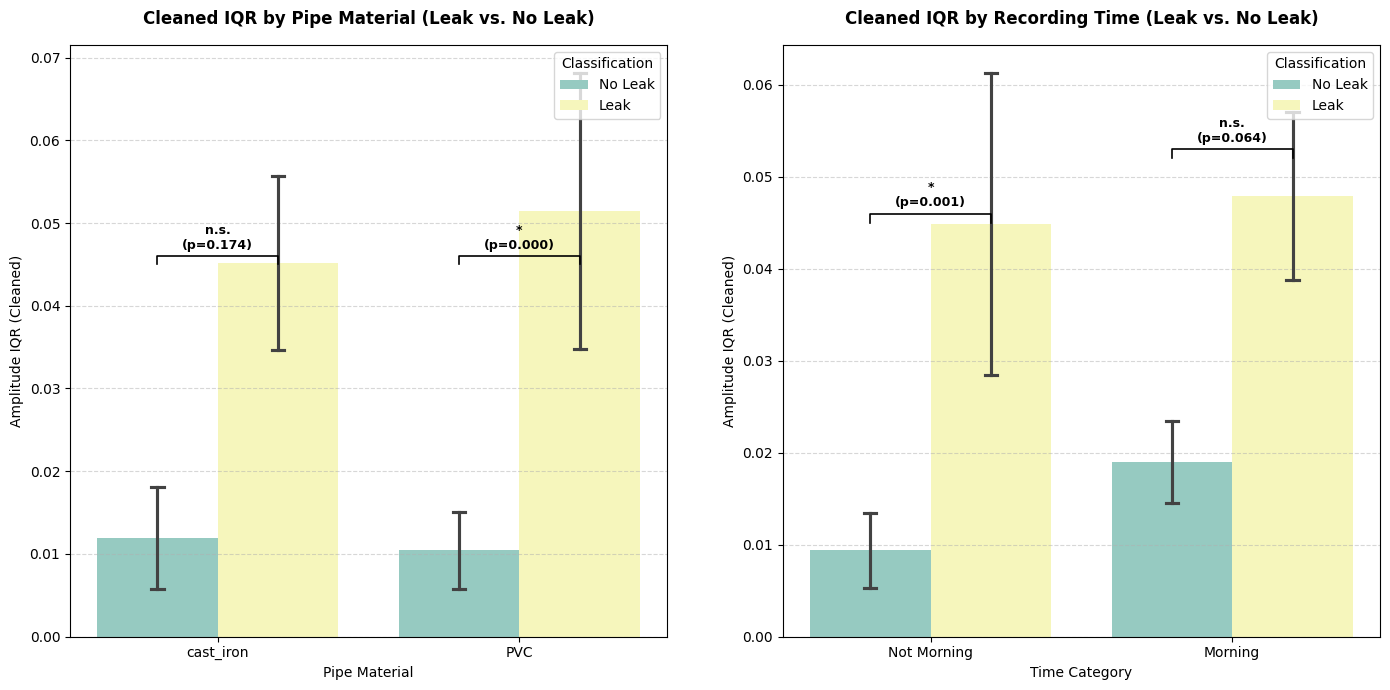

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind

# Ensure metadata and summary classifications are aligned
summary_with_meta = unlabeled_summary_df.copy()
summary_with_meta['clip_id'] = summary_with_meta['File Name'].apply(lambda x: x.replace('.csv', ''))

# Merge with metadata
merged_df = pd.merge(summary_with_meta, metadata_df, on='clip_id', how='inner')

# Classify time category
def classify_time(time_str):
    try:
        hour = int(time_str.split(':')[0])
        if 4 <= hour <= 7:
            return 'Morning'
        else:
            return 'Not Morning'
    except:
        return 'Unknown'

merged_df['Time Category'] = merged_df['recorded_at'].apply(classify_time)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# --- 1. Pipe Material Plot (Grouped Bars Side-by-Side) ---
sns.barplot(data=merged_df, x='pipe_material', y='Cleaned IQR', hue='Classification', palette='Set3', errorbar='sd', capsize=0.08, ax=axes[0])
axes[0].set_title('Cleaned IQR by Pipe Material (Leak vs. No Leak)', fontsize=12, fontweight='bold', pad=15)
axes[0].set_ylabel('Amplitude IQR (Cleaned)')
axes[0].set_xlabel('Pipe Material')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
axes[0].legend(title='Classification', loc='upper right')

# Calculate t-test statistics for Pipe Materials (Leak vs No Leak within each material)
pvc_leaks = merged_df[(merged_df['pipe_material'] == 'PVC') & (merged_df['Classification'] == 'Leak')]['Cleaned IQR']
pvc_noleaks = merged_df[(merged_df['pipe_material'] == 'PVC') & (merged_df['Classification'] == 'No Leak')]['Cleaned IQR']
t_pvc, p_pvc = ttest_ind(pvc_leaks, pvc_noleaks, equal_var=False)

ci_leaks = merged_df[(merged_df['pipe_material'] == 'cast_iron') & (merged_df['Classification'] == 'Leak')]['Cleaned IQR']
ci_noleaks = merged_df[(merged_df['pipe_material'] == 'cast_iron') & (merged_df['Classification'] == 'No Leak')]['Cleaned IQR']
t_ci, p_ci = ttest_ind(ci_leaks, ci_noleaks, equal_var=False)

# Annotation brackets for Pipe Material comparisons (aligned with the offset bars)
# PVC bracket (x-values offset around index 0)
x1, x2 = -0.2, 0.2
y, h = 0.045, 0.001
axes[0].plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.2, c='black')
stars_pvc = '*' if p_pvc < 0.05 else 'n.s.'
axes[0].text((x1+x2)*0.5, y+h*1.5, f"{stars_pvc}\n(p={p_pvc:.3f})", ha='center', va='bottom', color='black', fontsize=9, fontweight='bold')

# Cast Iron bracket (x-values offset around index 1)
x1, x2 = 0.8, 1.2
y, h = 0.045, 0.001
axes[0].plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.2, c='black')
stars_ci = '*' if p_ci < 0.05 else 'n.s.'
axes[0].text((x1+x2)*0.5, y+h*1.5, f"{stars_ci}\n(p={p_ci:.3f})", ha='center', va='bottom', color='black', fontsize=9, fontweight='bold')

# --- 2. Time Category Plot (Grouped Bars Side-by-Side) ---
sns.barplot(data=merged_df, x='Time Category', y='Cleaned IQR', hue='Classification', palette='Set3', errorbar='sd', capsize=0.08, ax=axes[1])
axes[1].set_title('Cleaned IQR by Recording Time (Leak vs. No Leak)', fontsize=12, fontweight='bold', pad=15)
axes[1].set_ylabel('Amplitude IQR (Cleaned)')
axes[1].set_xlabel('Time Category')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
axes[1].legend(title='Classification', loc='upper right')

# Calculate t-test statistics for Time Categories (Leak vs No Leak within each time segment)
morn_leaks = merged_df[(merged_df['Time Category'] == 'Morning') & (merged_df['Classification'] == 'Leak')]['Cleaned IQR']
morn_noleaks = merged_df[(merged_df['Time Category'] == 'Morning') & (merged_df['Classification'] == 'No Leak')]['Cleaned IQR']
t_morn, p_morn = ttest_ind(morn_leaks, morn_noleaks, equal_var=False)

nonmorn_leaks = merged_df[(merged_df['Time Category'] == 'Not Morning') & (merged_df['Classification'] == 'Leak')]['Cleaned IQR']
nonmorn_noleaks = merged_df[(merged_df['Time Category'] == 'Not Morning') & (merged_df['Classification'] == 'No Leak')]['Cleaned IQR']
t_nonmorn, p_nonmorn = ttest_ind(nonmorn_leaks, nonmorn_noleaks, equal_var=False)

# Annotation brackets for Time Category comparisons
# Morning bracket (x-values offset around index 0)
x1, x2 = -0.2, 0.2
y, h = 0.045, 0.001
axes[1].plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.2, c='black')
stars_morn = '*' if p_morn < 0.05 else 'n.s.'
axes[1].text((x1+x2)*0.5, y+h*1.5, f"{stars_morn}\n(p={p_morn:.3f})", ha='center', va='bottom', color='black', fontsize=9, fontweight='bold')

# Not Morning bracket (x-values offset around index 1)
x1, x2 = 0.8, 1.2
y, h = 0.052, 0.001
axes[1].plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.2, c='black')
stars_nonmorn = '*' if p_nonmorn < 0.05 else 'n.s.'
axes[1].text((x1+x2)*0.5, y+h*1.5, f"{stars_nonmorn}\n(p={p_nonmorn:.3f})", ha='center', va='bottom', color='black', fontsize=9, fontweight='bold')

plt.tight_layout(w_pad=4)
plt.show()